# Notebook 2. From an ensemble to a probability

**Predicting Flash Floods in Working Landscapes**, Module 3, Event based evaluation and forecast skill
CUAHSI Water Science Exchange 2026, University of Missouri, Saturday November 14, 2026
Humberto Vergara and Mohamed Abdelkader, University of Iowa, IIHR Hydroscience and Engineering

## What this notebook does

Notebook 1 showed that one HyMOD run hides a large uncertainty. The operational answer is to sample many plausible answers. That collection is the forecast ensemble. Here we build it, look at it, and convert it into the product a forecaster issues, a probability of exceeding a flood threshold. Notebooks 3 and 4 judge whether those probabilities are any good.

Module objective covered here. Turn an ensemble of simulations into a probability of exceeding a flood threshold.

| Step | What we do |
|---|---|
| 1 | Rebuild the data, the control run and the flood threshold |
| 2 | Build a 100 member ensemble by perturbing rainfall and parameters |
| 3 | Look at it as spaghetti and as a band |
| 4 | Turn it into a probability of exceedance, day by day |
| 5 | Ask what drives the spread |
| 6 | Your turn |

## 0. Setup

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/AHWALab/Water-Science-Exchange-Workshop.git"
BRANCH = "module-3-evaluation"

# In Colab the helper files are not here yet. Copy the branch (public, no account needed).
if not Path("hymod_tools.py").exists():
    if not Path("Water-Science-Exchange-Workshop").is_dir():
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "-b", BRANCH, REPO_URL], check=True)
    os.chdir("Water-Science-Exchange-Workshop/notebooks")
sys.path.insert(0, os.getcwd())
print("Working folder:", os.getcwd())

Working folder: /home/claude/wse/notebooks


In [2]:
import inspect
import numpy as np
import matplotlib.pyplot as plt

import hymod_tools as h
import nb_style
from nb_style import PALETTE, threshold_band
nb_style.set_style()

## 1. Rebuild the experiment

Same data, same five year window, same control run as Notebook 1. One new ingredient, the flood threshold, which turns a continuous flow into a yes or no event.

In [3]:
# Step 1. Data and the evaluation window.
PP, PET, QQ = h.load_leaf_river("LeafCatch.dat")
N_EVAL = 365 * 5
Qobs = QQ[:N_EVAL]

# Step 2. The deterministic control run (calibrated parameters from Notebook 1).
Qctrl = h.hymod01(PP[:N_EVAL], PET[:N_EVAL], h.CONTROL_PARS)["Q"]

In [4]:
# Step 3. The flood threshold, one quarter of the mean annual maximum flow over the full record.
flood_th = h.flood_threshold(QQ, fraction=0.25)

# Step 4. Observed events (1 on days at or above the threshold) and their long run frequency.
obs_events = (Qobs >= flood_th).astype(int)
climatology = obs_events.mean()                 # the base rate, our reference forecast later
print(f"flood threshold      {flood_th:.3f} mm/day")
print(f"event days in window {obs_events.sum()} of {N_EVAL}")
print(f"climatology          {climatology:.4f}, about {100 * climatology:.1f} percent of days")

flood threshold      5.000 mm/day
event days in window 115 of 1825
climatology          0.0630, about 6.3 percent of days


## 2. The ensemble recipe

Each member is one plausible version of reality. Two sources of uncertainty are perturbed.

- Rainfall. The whole precipitation series is multiplied by one random factor between 0 and 1.2. A crude way to say that the storm depth is uncertain.
- Parameters. `Huz`, `B`, `Alp` and `Kq` are drawn from wide ranges. `Nq` and `Ks` stay fixed.

This ensemble is deliberately wide and not centred on the control run. It is an imperfect forecast system on purpose, so that the verification tools of Notebooks 3 and 4 have flaws to find.

In [5]:
print(inspect.getsource(h.generate_ensemble))

def generate_ensemble(PP, PET, n_days, Nens=100, seed=7, max_rain_multiplier=1.2):
    """Generate a HyMOD forecast ENSEMBLE by perturbing forcing + parameters.

    Reproduces EnsembleGeneration_HyModMain.m. Each member is one plausible
    catchment+storm: the whole rain series is scaled by a random factor in
    [0, max_rain_multiplier) (rainfall uncertainty), and Huz, B, Alp, Kq are drawn
    from their ranges (Nq, Ks fixed, as in the source). Kq ~ Exponential(1)
    normalised to (0,1].

    Returns: ensemble (Nens x n_days streamflow array), members (list of dicts).
    """
    rng = np.random.default_rng(seed)
    # Pre-draw Kq for all members, normalise to (0,1] (mirrors MATLAB randg/max):
    kq_draws = rng.gamma(shape=1.0, size=Nens)     # Exp(1) == Gamma(shape=1)
    kq_draws = kq_draws / kq_draws.max()
    ensemble = np.zeros((Nens, n_days))
    members = []
    for i in range(Nens):
        mult = max_rain_multiplier * rng.random()  # rainfall perturbation
        Pars = {

In [6]:
# Step 1. Build the ensemble. The fixed seed makes every notebook build the identical ensemble.
ensemble, members = h.generate_ensemble(PP, PET, N_EVAL, Nens=100, seed=7)
Nens = ensemble.shape[0]
print(f"ensemble shape {ensemble.shape}, that is {Nens} members by {N_EVAL} days")

ensemble shape (100, 1825), that is 100 members by 1825 days


In [7]:
# Step 2. Two simple summaries. The ensemble mean, and the member to member spread.
ens_mean = ensemble.mean(axis=0)
print(f"ensemble mean from {ens_mean.min():.2f} to {ens_mean.max():.2f} mm/day")
print(f"mean daily spread (standard deviation across members) {ensemble.std(axis=0).mean():.3f} mm/day")

ensemble mean from 0.00 to 2.11 mm/day
mean daily spread (standard deviation across members) 0.846 mm/day


## 3. Looking at the ensemble

The spaghetti plot. Every grey line is one member, the dashed black line is the observed flow, the orange line is the ensemble mean, the red line is the flood threshold. Where the grey band straddles the threshold, the forecast is uncertain about the flood.

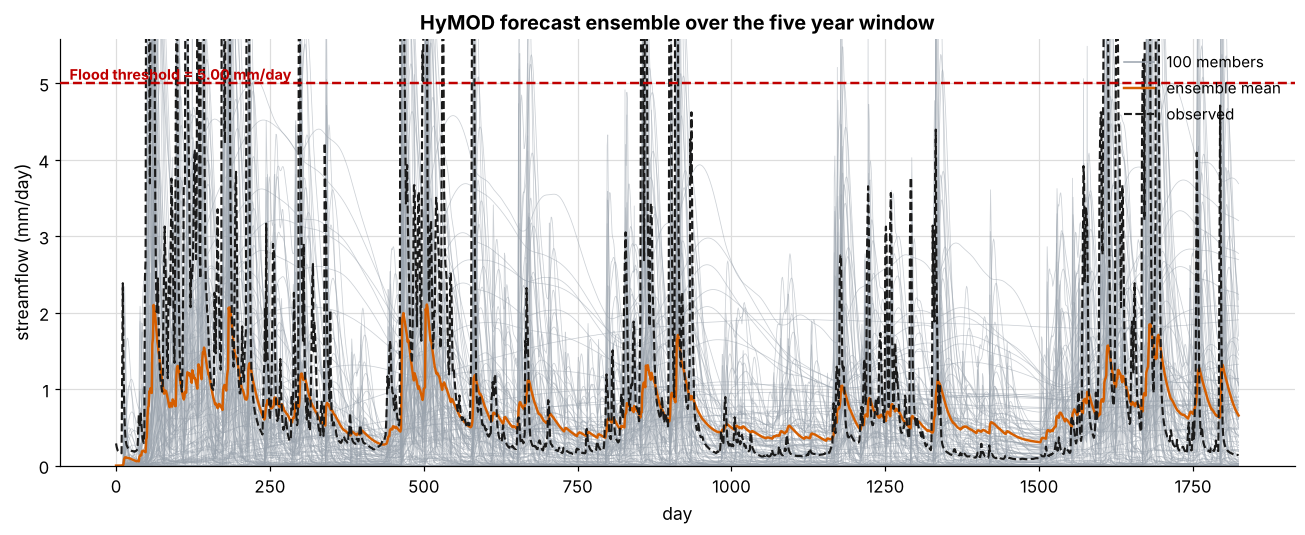

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ensemble.T, color=PALETTE["ensemble"], lw=0.5, alpha=0.5)
ax.plot([], [], color=PALETTE["ensemble"], lw=1, label=f"{Nens} members")
ax.plot(ens_mean, color=PALETTE["ens_mean"], lw=1.6, label="ensemble mean")
ax.plot(Qobs, color=PALETTE["obs"], lw=1.4, ls="--", label="observed")
threshold_band(ax, flood_th)
ax.set_xlabel("day"); ax.set_ylabel("streamflow (mm/day)")
ax.set_title("HyMOD forecast ensemble over the five year window")
ax.set_ylim(0, np.percentile(ensemble, 99.5))
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

One event. The members disagree about the timing and the height of the peak. That disagreement is the forecast uncertainty, and the threshold crossing is what we will score.

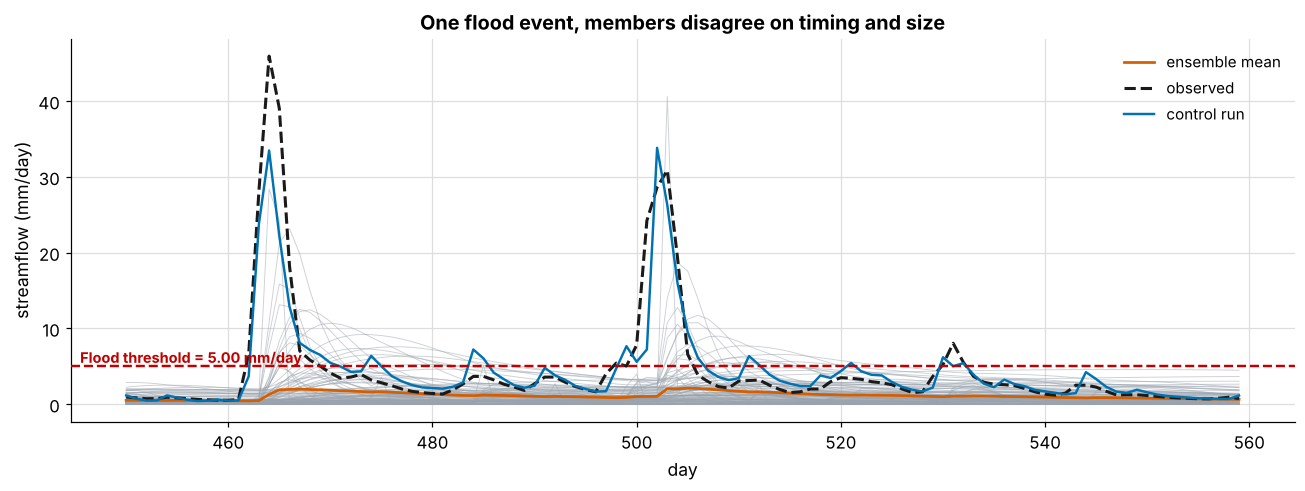

In [9]:
event = slice(450, 560)
xs = np.arange(event.start, event.stop)

fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(xs, ensemble[:, event].T, color=PALETTE["ensemble"], lw=0.6, alpha=0.5)
ax.plot(xs, ens_mean[event], color=PALETTE["ens_mean"], lw=1.8, label="ensemble mean")
ax.plot(xs, Qobs[event], color=PALETTE["obs"], lw=2, ls="--", label="observed")
ax.plot(xs, Qctrl[event], color=PALETTE["control"], lw=1.6, label="control run")
threshold_band(ax, flood_th)
ax.set_xlabel("day"); ax.set_ylabel("streamflow (mm/day)")
ax.set_title("One flood event, members disagree on timing and size")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

The band. Forecasters often show percentiles instead of one hundred lines. A wide band means high uncertainty. A band that misses the observation means the ensemble is too narrow, a flaw the rank histogram of Notebook 4 measures.

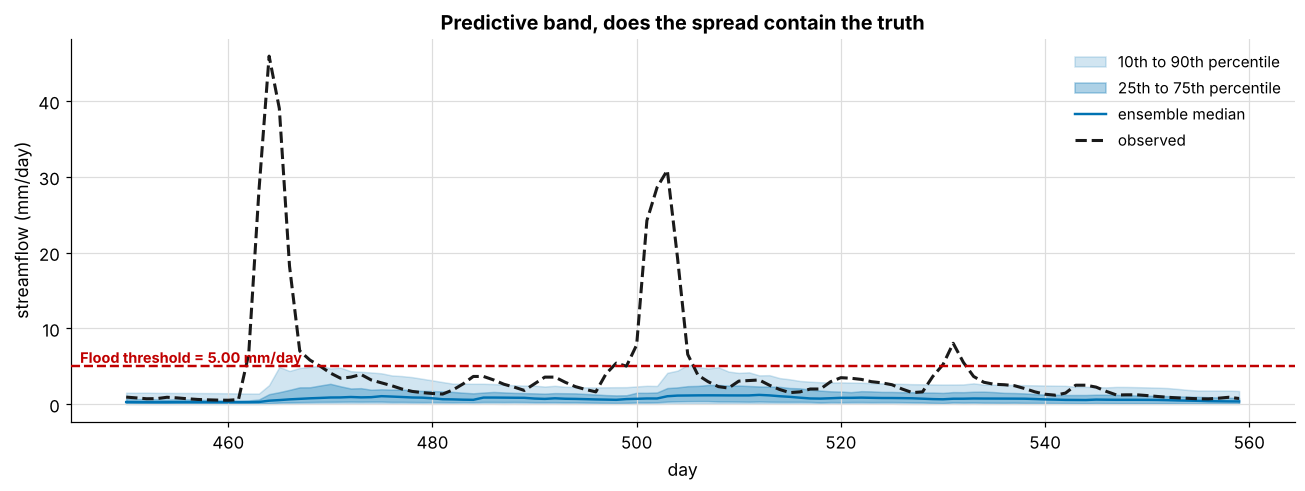

In [10]:
# Percentiles across the members, day by day.
p10, p25, p50, p75, p90 = (np.percentile(ensemble, q, axis=0) for q in (10, 25, 50, 75, 90))

fig, ax = plt.subplots(figsize=(12, 4.6))
ax.fill_between(xs, p10[event], p90[event], color=PALETTE["control"], alpha=0.18, label="10th to 90th percentile")
ax.fill_between(xs, p25[event], p75[event], color=PALETTE["control"], alpha=0.32, label="25th to 75th percentile")
ax.plot(xs, p50[event], color=PALETTE["control"], lw=1.6, label="ensemble median")
ax.plot(xs, Qobs[event], color=PALETTE["obs"], lw=2, ls="--", label="observed")
threshold_band(ax, flood_th)
ax.set_xlabel("day"); ax.set_ylabel("streamflow (mm/day)")
ax.set_title("Predictive band, does the spread contain the truth")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

## 4. From ensemble to probability

The key step. On each day we ask one question. What fraction of the members exceeds the flood threshold? That fraction is the forecast probability of a flood,

$$ p_t = \frac{1}{N}\sum_{i=1}^{N} \mathbf{1}\left[Q_{i,t} \ge Q_{thr}\right]. $$

If 70 of 100 members exceed the threshold, the forecast reads 70 percent. This single number per day is what Notebooks 3 and 4 verify.

In [11]:
# Step 1. Indicator matrix, 1 where a member exceeds the threshold.
exceed_matrix = (ensemble >= flood_th).astype(int)        # shape (Nens, N_EVAL)

# Step 2. Forecast probability per day, the mean of the indicator down the member axis.
prob_exceed = exceed_matrix.mean(axis=0)                  # shape (N_EVAL,)
print(f"forecast probability from {prob_exceed.min():.2f} to {prob_exceed.max():.2f}, mean {prob_exceed.mean():.3f}")
print(f"compare the mean forecast probability with the climatology {climatology:.3f}")

forecast probability from 0.00 to 0.15, mean 0.007
compare the mean forecast probability with the climatology 0.063


How one day becomes one number. Pick the most uncertain day, the one with a forecast closest to 50 percent, and show the member distribution. The probability is the area to the right of the threshold.

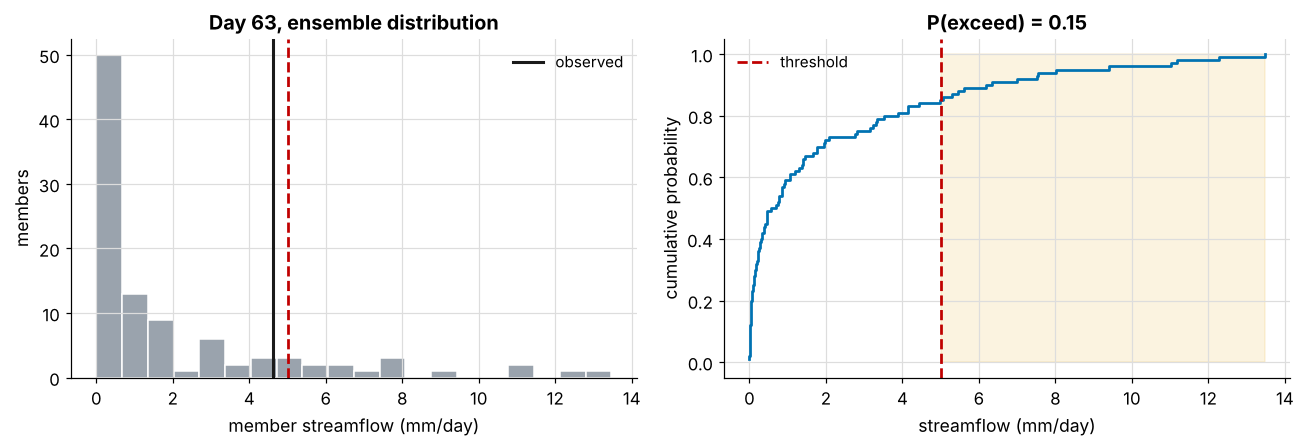

day 63: 15 of 100 members exceed, probability 0.15, observed event 0


In [12]:
day = int(np.argmin(np.abs(prob_exceed - 0.5)))      # the day closest to 50 percent
day_members = ensemble[:, day]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Histogram of the 100 member flows on that day.
axes[0].hist(day_members, bins=20, color=PALETTE["ensemble"], edgecolor="white")
axes[0].axvline(flood_th, color=PALETTE["threshold"], ls="--", lw=1.8)
axes[0].axvline(Qobs[day], color=PALETTE["obs"], lw=2, label="observed")
axes[0].set_xlabel("member streamflow (mm/day)"); axes[0].set_ylabel("members")
axes[0].set_title(f"Day {day}, ensemble distribution"); axes[0].legend()

# Empirical cumulative distribution. The exceedance probability is one minus the CDF at the threshold.
sx = np.sort(day_members); cdf = np.arange(1, Nens + 1) / Nens
axes[1].step(sx, cdf, where="post", color=PALETTE["control"], lw=1.8)
axes[1].axvline(flood_th, color=PALETTE["threshold"], ls="--", lw=1.8, label="threshold")
axes[1].fill_betweenx([0, 1], flood_th, sx.max(), color=PALETTE["skill"], alpha=0.12)
axes[1].set_xlabel("streamflow (mm/day)"); axes[1].set_ylabel("cumulative probability")
axes[1].set_title(f"P(exceed) = {prob_exceed[day]:.2f}"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"day {day}: {exceed_matrix[:, day].sum()} of {Nens} members exceed, "
      f"probability {prob_exceed[day]:.2f}, observed event {obs_events[day]}")

The probability as a time series, with the observed events marked. High on event days and low on quiet days means skill. The next two notebooks make that judgement rigorous.

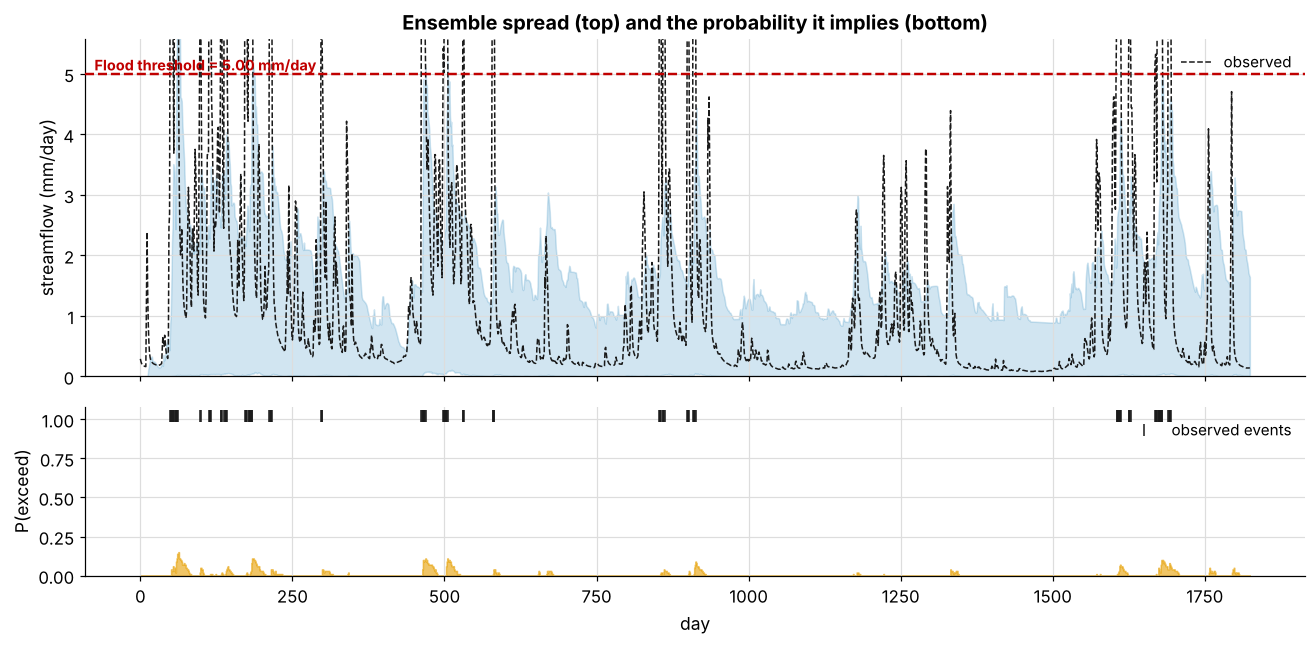

In [13]:
fig, (axtop, axbot) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

# Top, the ensemble band, the observations and the threshold.
axtop.fill_between(np.arange(N_EVAL), p10, p90, color=PALETTE["control"], alpha=0.18)
axtop.plot(Qobs, color=PALETTE["obs"], lw=1.0, ls="--", label="observed")
threshold_band(axtop, flood_th)
axtop.set_ylabel("streamflow (mm/day)"); axtop.set_ylim(0, np.percentile(ensemble, 99.5))
axtop.set_title("Ensemble spread (top) and the probability it implies (bottom)")
axtop.legend(loc="upper right")

# Bottom, the forecast probability with a tick on every observed event day.
axbot.fill_between(np.arange(N_EVAL), prob_exceed, color=PALETTE["skill"], alpha=0.6, step="mid")
ev = np.where(obs_events == 1)[0]
axbot.plot(ev, np.full_like(ev, 1.02, dtype=float), "|", color=PALETTE["obs"], ms=8, label="observed events")
axbot.set_ylim(0, 1.08); axbot.set_ylabel("P(exceed)"); axbot.set_xlabel("day")
axbot.legend(loc="upper right"); plt.tight_layout(); plt.show()

## 5. What drives the spread

Every member recorded its perturbations, so we can ask which uncertainty matters most. Plot each member's mean flow against its rainfall multiplier and against its `Kq`.

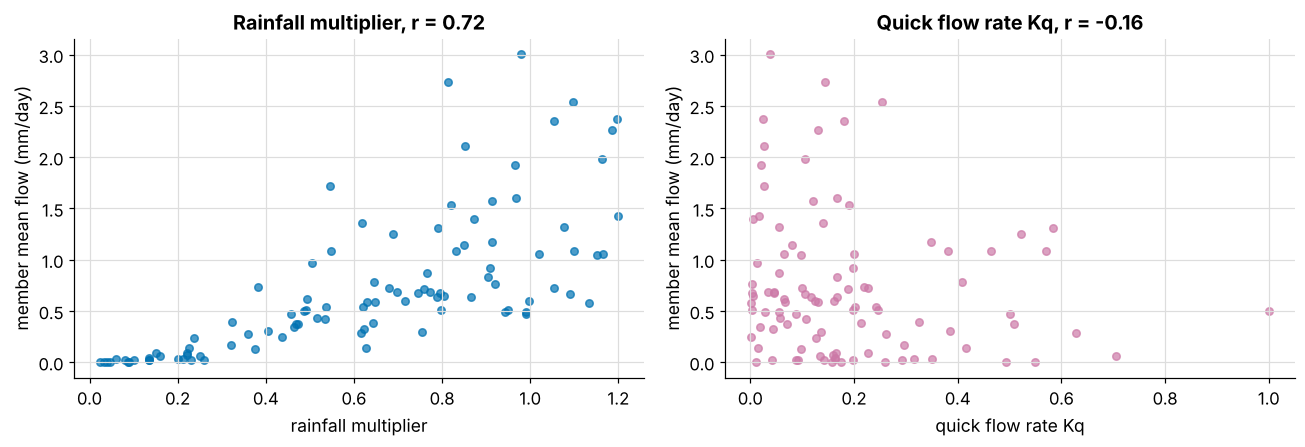

In [14]:
mult = np.array([m["multiplier"] for m in members])
kq = np.array([m["Kq"] for m in members])
member_mean_flow = ensemble.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(mult, member_mean_flow, s=24, color=PALETTE["control"], alpha=0.7)
axes[0].set_xlabel("rainfall multiplier"); axes[0].set_ylabel("member mean flow (mm/day)")
axes[0].set_title(f"Rainfall multiplier, r = {np.corrcoef(mult, member_mean_flow)[0, 1]:.2f}")
axes[1].scatter(kq, member_mean_flow, s=24, color=PALETTE["accent2"], alpha=0.7)
axes[1].set_xlabel("quick flow rate Kq"); axes[1].set_ylabel("member mean flow (mm/day)")
axes[1].set_title(f"Quick flow rate Kq, r = {np.corrcoef(kq, member_mean_flow)[0, 1]:.2f}")
plt.tight_layout(); plt.show()

The rainfall multiplier dominates. That matches operational experience, precipitation input error is usually the largest source of streamflow forecast uncertainty.

## 6. Your turn

How many members does a probability need? Repeat the probability calculation with the first 20 members only and compare it with the 100 member version.

In [15]:
#################### Your Code Goes Here #########################
# Step 1. Keep the first 20 members of the ensemble (rows of the array).
small = ensemble[:20]

# Step 2. Probability of exceedance from those 20 members, same recipe as section 4.
prob_small = (small >= flood_th).mean(axis=0)

# Step 3. Compare with prob_exceed. Print the largest absolute difference on any day
#         and the correlation between the two series (np.corrcoef).
print(f"largest difference on a day {np.abs(prob_small - prob_exceed).max():.2f}")
print(f"correlation between the two series {np.corrcoef(prob_small, prob_exceed)[0, 1]:.3f}")
###################################################################

largest difference on a day 0.09
correlation between the two series 0.875


Questions for the group

1. With 20 members the probability can only take 21 values. What does that do to a forecast of a rare event?
2. The rainfall multiplier is drawn between 0 and 1.2, so the average member sees less rain than observed. What bias do you expect in the probabilities? Notebook 4 checks.

## Recap

- A 100 member ensemble from perturbed rainfall and parameters.
- Spaghetti, band, and the conversion to a probability of threshold exceedance on every day.
- The rainfall multiplier drives most of the spread.

We now hold the three objects the verification notebooks need, the observed events `obs_events`, the forecast probabilities `prob_exceed`, and the raw `ensemble`.

## References and credits

- Cloke, H. L. and F. Pappenberger, 2009. Ensemble flood forecasting, a review. Journal of Hydrology, 375, 613 to 626.
- Gupta, H. V., 2005. HyMOD tutorial code, HWR 521, University of Arizona, including `EnsembleGeneration_HyModMain.m`, the source of the ensemble recipe.
- Adapted from the Ensemble Forecast Evaluation series prepared by Humberto Vergara and Mohamed Abdelkader for the CIROH Summer Institute 2026.